<a href="https://colab.research.google.com/github/3B232095/2026_DL_hws/blob/main/hw4_2_jpynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.datasets import cifar10
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.21.0


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2134s 13us/step
原始訓練資料形狀: (50000, 32, 32, 3)
原始訓練標籤形狀: (50000, 1)
原始測試資料形狀: (10000, 32, 32, 3)
原始測試標籤形狀: (10000, 1)

正規化後訓練資料形狀: (50000, 32, 32, 3)
訓練標籤 one-hot 形狀: (50000, 10)
正規化後測試資料形狀: (10000, 32, 32, 3)
測試標籤 one-hot 形狀: (10000, 10)
像素值範圍: 0.0 到 1.0


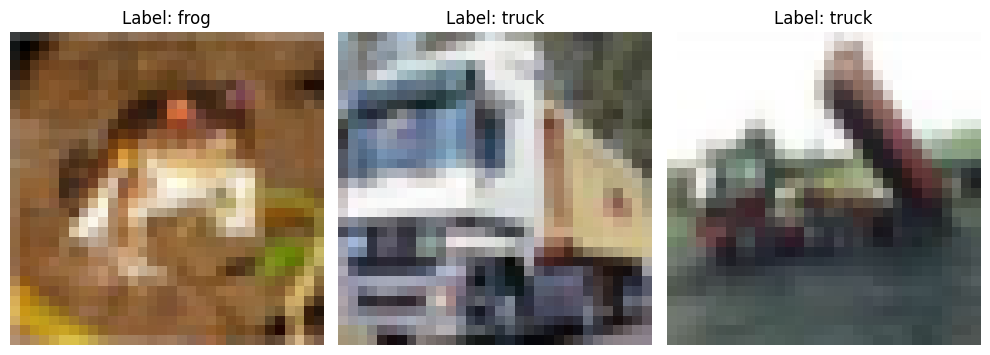

In [2]:
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

print("原始訓練資料形狀:", x_train.shape)
print("原始訓練標籤形狀:", y_train.shape)
print("原始測試資料形狀:", x_test.shape)
print("原始測試標籤形狀:", y_test.shape)

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# 將 (N, 1) 標籤轉成一維整數標籤，供顯示及混淆矩陣使用
y_train_int = y_train.reshape(-1)
y_test_int = y_test.reshape(-1)

# 分類模型使用 one-hot 標籤
y_train_cat = keras.utils.to_categorical(y_train_int, 10)
y_test_cat = keras.utils.to_categorical(y_test_int, 10)

print("\n正規化後訓練資料形狀:", x_train.shape)
print("訓練標籤 one-hot 形狀:", y_train_cat.shape)
print("正規化後測試資料形狀:", x_test.shape)
print("測試標籤 one-hot 形狀:", y_test_cat.shape)
print("像素值範圍:", x_train.min(), "到", x_train.max())

class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.figure(figsize=(10, 4))
for i in range(3):
    plt.subplot(1, 3, i + 1)
    plt.imshow(x_train[i])
    plt.title(f"Label: {class_names[y_train_int[i]]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


In [5]:
model = keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    # 第 01 層：Conv2D，參數=(5×5×3+1)×32=2,432
    layers.Conv2D(32, (5, 5), activation="relu", padding="same", name="conv_01"),
    # 第 02 層：Dropout，不含可訓練參數
    layers.Dropout(0.25, name="dropout_02"),
    # 第 03 層：MaxPooling，不含可訓練參數
    layers.MaxPooling2D((2, 2), name="pool_03"),

    # 第 04 層：Conv2D，參數=(3×3×32+1)×64=18,496
    layers.Conv2D(64, (3, 3), activation="relu", padding="same", name="conv_04"),
    # 第 05 層：Dropout，不含可訓練參數
    layers.Dropout(0.25, name="dropout_05"),
    # 第 06 層：MaxPooling，不含可訓練參數
    layers.MaxPooling2D((2, 2), name="pool_06"),

    # 第 07 層：Flatten，不含可訓練參數
    layers.Flatten(name="flatten_07"),
    # 第 08 層：Dropout，不含可訓練參數
    layers.Dropout(0.25, name="dropout_08"),
    # 第 09 層：Dense，參數=(Flatten 單元數+1)×1024
    layers.Dense(1024, activation="relu", name="dense_09"),
    # 第 10 層：Dropout，不含可訓練參數
    layers.Dropout(0.25, name="dropout_10"),
    # 第 11 層：Dense，參數=(1024+1)×10=10,250
    layers.Dense(10, activation="softmax", name="output_11")
], name="cifar10_hw4_2_cnn")

model.summary()
print("\n逐層 Output Shape / Parameters：")
for i, layer in enumerate(model.layers, start=1):
    batch_output_shape = (128,) + tuple(layer.output.shape[1:])
    print(
        f"第 {i:02d} 層 {layer.name:15s} "
        f"batch_output_shape={batch_output_shape}, "
        f"params={layer.count_params():,}"
    )
print("\n參數計算：")
print("第 01 層：(5×5×3 + 1) × 32 =", (5*5*3+1)*32)
print("第 04 層：(3×3×32 + 1) × 64 =", (3*3*32+1)*64)
print("第 09 層：(Flatten 輸出單元數 + 1) × 1024")
print("第 11 層：(1024 + 1) × 10 =", (1024+1)*10)
print("Dropout、MaxPooling、Flatten 均沒有可訓練參數。")

Model: "cifar10_hw4_2_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv_01 (Conv2D)                │ (None, 32, 32, 32)     │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_02 (Dropout)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_03 (MaxPooling2D)          │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_04 (Conv2D)                │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_05 (Dropout)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool_06 (MaxPooling2D)          │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_07 (Flatten)            │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_08 (Dropout)            │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_09 (Dense)                │ (None, 1024)           │     4,195,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_11 (Dense)               │ (None, 10)             │        10,250 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,226,506 (16.12 MB)

 Trainable params: 4,226,506 (16.12 MB)

 Non-trainable params: 0 (0.00 B)


逐層 Output Shape / Parameters：
第 01 層 conv_01         batch_output_shape=(128, 32, 32, 32), params=2,432
第 02 層 dropout_02      batch_output_shape=(128, 32, 32, 32), params=0
第 03 層 pool_03         batch_output_shape=(128, 16, 16, 32), params=0
第 04 層 conv_04         batch_output_shape=(128, 16, 16, 64), params=18,496
第 05 層 dropout_05      batch_output_shape=(128, 16, 16, 64), params=0
第 06 層 pool_06         batch_output_shape=(128, 8, 8, 64), params=0
第 07 層 flatten_07      batch_output_shape=(128, 4096), params=0
第 08 層 dropout_08      batch_output_shape=(128, 4096), params=0
第 09 層 dense_09        batch_output_shape=(128, 1024), params=4,195,328
第 10 層 dropout_10      batch_output_shape=(128, 1024), params=0
第 11 層 output_11       batch_output_shape=(128, 10), params=10,250

參數計算：
第 01 層：(5×5×3 + 1) × 32 = 2432
第 04 層：(3×3×32 + 1) × 64 = 18496
第 09 層：(Flatten 輸出單元數 + 1) × 1024
第 11 層：(1024 + 1) × 10 = 10250
Dropout、MaxPooling、Flatten 均沒有可訓練參數。


In [6]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

EPOCHS = 20
BATCH_SIZE = 128

# 每批輸入形狀為 (128, 32, 32, 3)，最後一批可能少於 128 張
print("批次訓練 Input Shape:", (BATCH_SIZE, 32, 32, 3))
print("每層 Output Shape / Parameters 請以上方 model.summary() 為準。")

history = model.fit(
    x_train, y_train_cat,
    validation_split=0.20,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    verbose=1
)


批次訓練 Input Shape: (128, 32, 32, 3)
每層 Output Shape / Parameters 請以上方 model.summary() 為準。
Epoch 1/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 137s 433ms/step - accuracy: 0.4308 - loss: 1.5783 - val_accuracy: 0.5454 - val_loss: 1.3789
Epoch 2/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 433ms/step - accuracy: 0.5599 - loss: 1.2292 - val_accuracy: 0.6053 - val_loss: 1.1985
Epoch 3/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 432ms/step - accuracy: 0.6213 - loss: 1.0680 - val_accuracy: 0.6463 - val_loss: 1.0848
Epoch 4/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 131s 418ms/step - accuracy: 0.6631 - loss: 0.9561 - val_accuracy: 0.6639 - val_loss: 1.0168
Epoch 5/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 146s 430ms/step - accuracy: 0.6988 - loss: 0.8546 - val_accuracy: 0.6835 - val_loss: 0.9577
Epoch 6/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 140s 425ms/step - accuracy: 0.7331 - loss: 0.7591 - val_accuracy: 0.6836 - val_loss: 0.9344
Epoch 7/20
313/313 ━━━━━━━━━━━━━━━━━━━━ 146s 437ms/step - accuracy: 0.7630 - loss: 0.6780 - val_accuracy: 0.6920 - val_

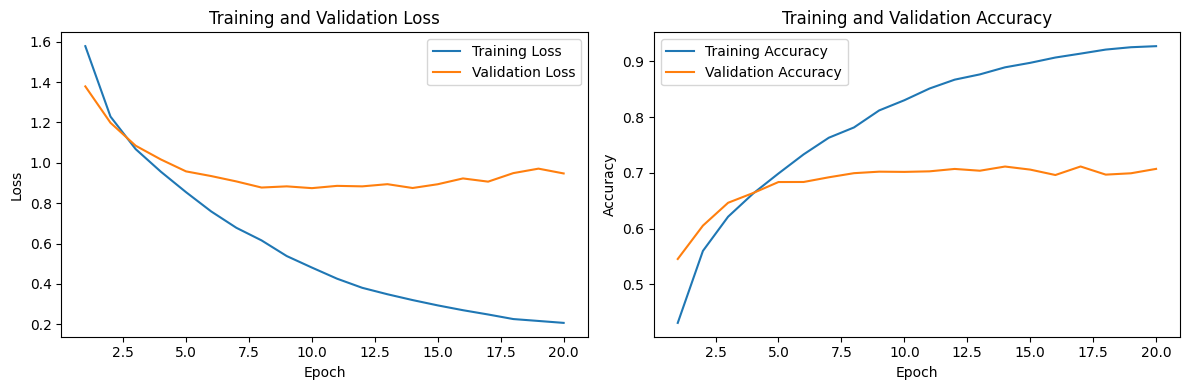

In [7]:
epochs_range = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["loss"], label="Training Loss")
plt.plot(epochs_range, history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs_range, history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


In [8]:
test_loss, test_accuracy = model.evaluate(x_test, y_test_cat, verbose=1)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy * 100:.2f}%)")


313/313 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.7066 - loss: 0.9466
Test Loss: 0.9466
Test Accuracy: 0.7066 (70.66%)


79/79 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step


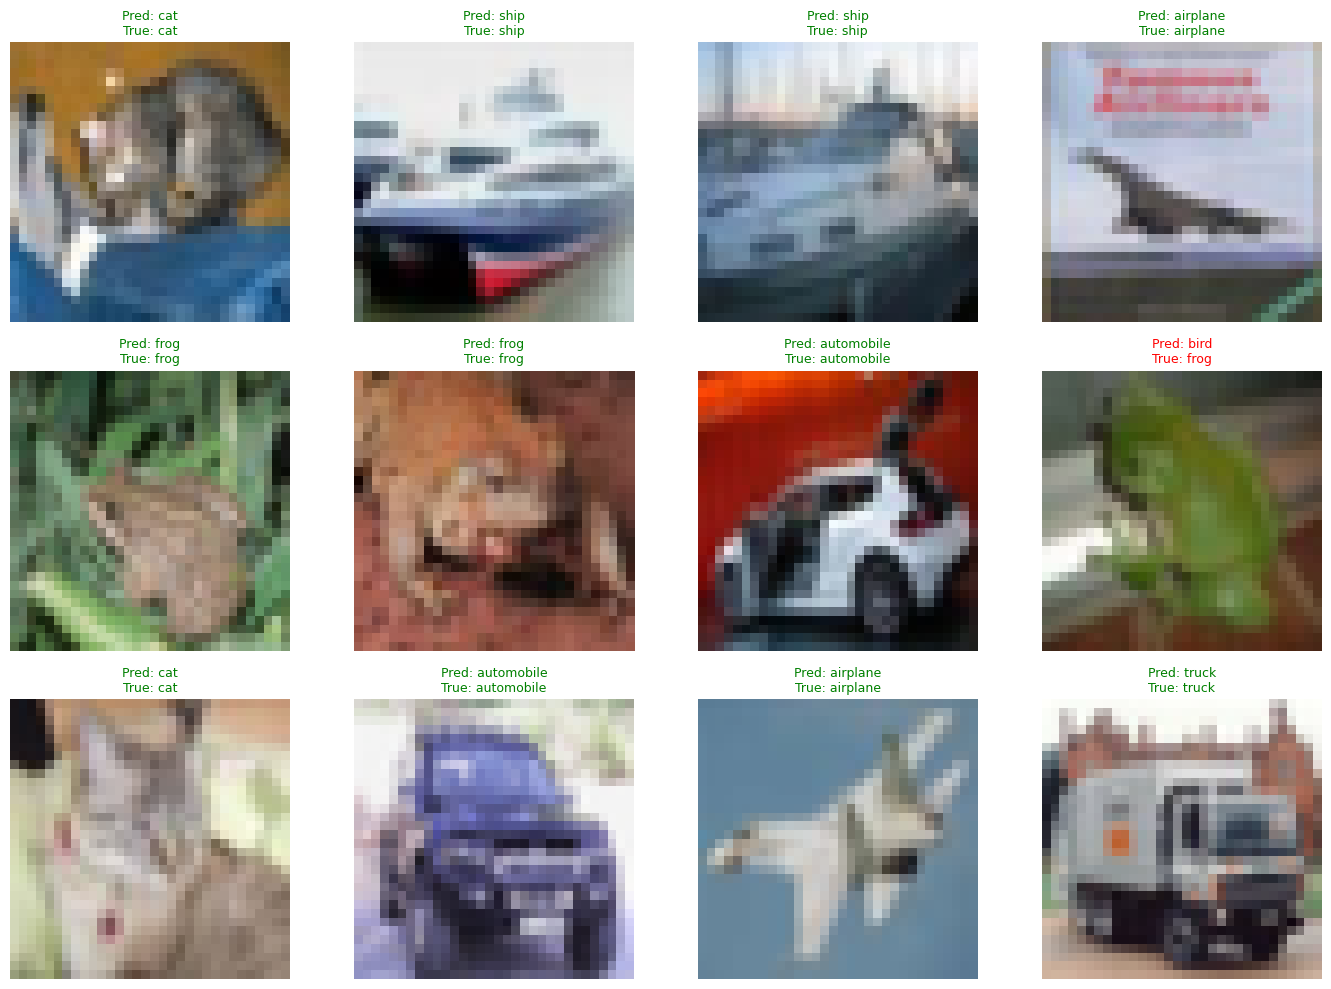

In [9]:
y_prob = model.predict(x_test, batch_size=128, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

show_n = 12
plt.figure(figsize=(14, 10))
for i in range(show_n):
    plt.subplot(3, 4, i + 1)
    plt.imshow(x_test[i])
    pred_name = class_names[y_pred[i]]
    true_name = class_names[y_test_int[i]]
    color = "green" if y_pred[i] == y_test_int[i] else "red"
    plt.title(f"Pred: {pred_name}\nTrue: {true_name}", color=color, fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()


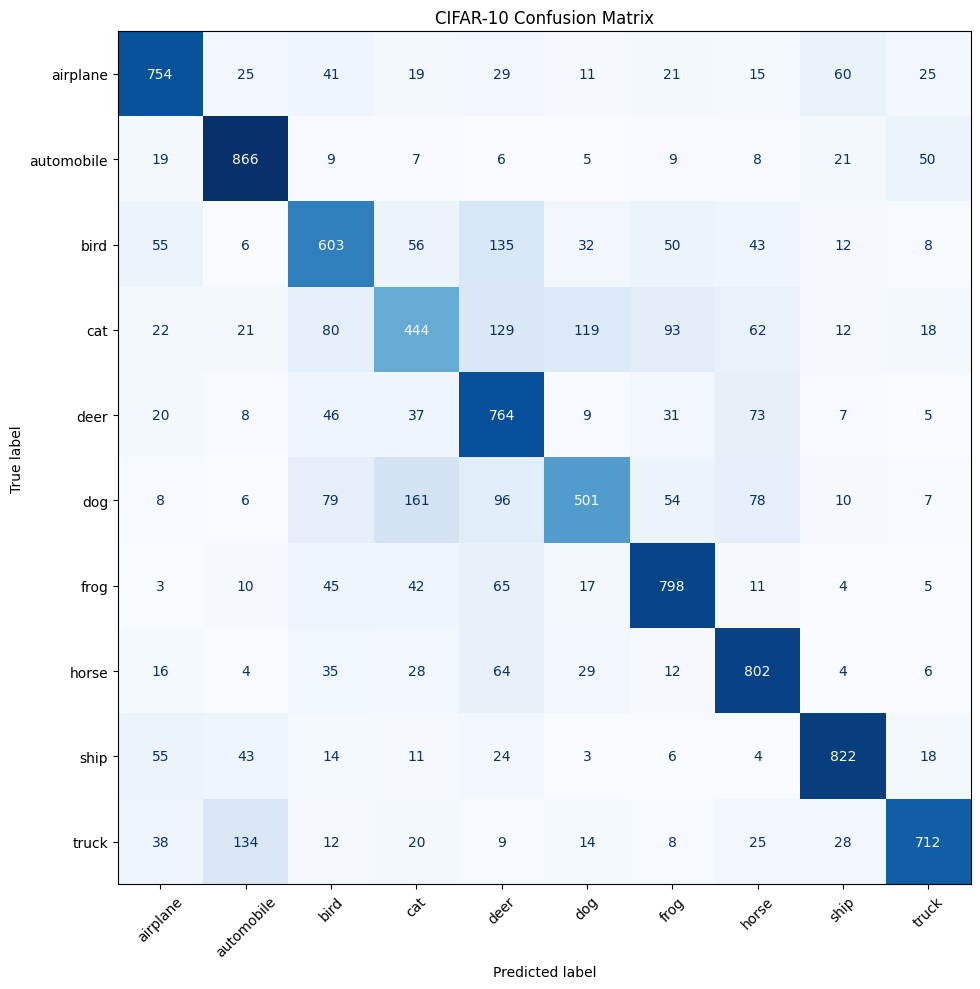

              precision    recall  f1-score   support

    airplane       0.76      0.75      0.76      1000
  automobile       0.77      0.87      0.82      1000
        bird       0.63      0.60      0.61      1000
         cat       0.54      0.44      0.49      1000
        deer       0.58      0.76      0.66      1000
         dog       0.68      0.50      0.58      1000
        frog       0.74      0.80      0.77      1000
       horse       0.72      0.80      0.76      1000
        ship       0.84      0.82      0.83      1000
       truck       0.83      0.71      0.77      1000

    accuracy                           0.71     10000
   macro avg       0.71      0.71      0.70     10000
weighted avg       0.71      0.71      0.70     10000



In [10]:
cm = confusion_matrix(y_test_int, y_pred)
fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("CIFAR-10 Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(y_test_int, y_pred, target_names=class_names))


In [14]:
from google.colab import drive
import os

# 掛載 Google Drive
drive.mount('/content/drive')

# 建立模型存放資料夾
model_dir = '/content/drive/MyDrive/2026_DL_hws'
os.makedirs(model_dir, exist_ok=True)

# 儲存模型
model.save(model_dir + '/hw4-2_model.keras')

print("HW4-2 模型已儲存到 Google Drive！")

Mounted at /content/drive
HW4-2 模型已儲存到 Google Drive！


In [15]:
from google.colab import drive
drive.mount('/content/drive')

# 讀取 HW4-1 模型
previous_path = '/content/drive/MyDrive/2026_DL_hws/hw4-1_model.keras'

previous_model = keras.models.load_model(previous_path)

prev_loss, prev_acc = previous_model.evaluate(
    x_test, y_test_cat, verbose=0
)

print(f"HW4-1 Test Loss: {prev_loss:.4f}")
print(f"HW4-1 Test Accuracy: {prev_acc:.4f}")

print(f"HW4-2 Test Loss: {test_loss:.4f}")
print(f"HW4-2 Test Accuracy: {test_accuracy:.4f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
HW4-1 Test Loss: 1.6432
HW4-1 Test Accuracy: 0.6615
HW4-2 Test Loss: 0.9466
HW4-2 Test Accuracy: 0.7066
